In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
wine_quality = fetch_ucirepo(id=186) 
  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 
  
# metadata 
print(wine_quality.metadata) 
  
# variable information 
print(wine_quality.variables) 


{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

In [5]:
def classificar_vinho(nota):
    if nota <= 5:
        return 'ruim'
    elif nota <= 7:
        return 'medio'
    else:
        return 'bom'

y_categorico = y['quality'].apply(classificar_vinho)

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y_categorico, test_size=0.2, random_state=42, stratify=y_categorico)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


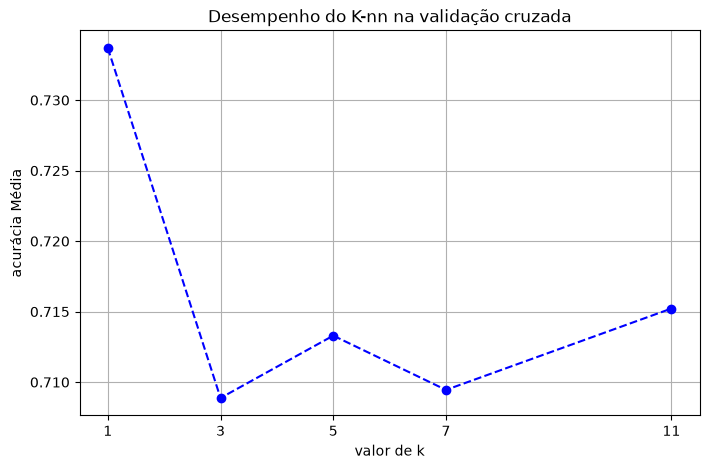

In [7]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import numpy as np

valores_k = [1, 3, 5, 7, 11]
acuracias_medias = []

for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring='accuracy')

    acuracias_medias.append(np.mean(scores))

plt.figure(figsize=(8, 5))
plt.plot(valores_k, acuracias_medias, marker = 'o', linestyle='dashed', color='b')
plt.title('Desempenho do K-nn na validação cruzada')
plt.xlabel('valor de k')
plt.ylabel('acurácia Média')
plt.xticks(valores_k)
plt.grid(True)
plt.show()

In [9]:
from sklearn.metrics import confusion_matrix
knn_teste = KNeighborsClassifier(n_neighbors=1)

knn_teste.fit(X_train_scaled, y_train)

y_pred = knn_teste.predict(X_test_scaled)

print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred))

from sklearn.metrics import classification_report

print("Relatório de Métricas por Classe:")
# O Scikit-Learn listará as classes em ordem alfabética: bom, medio, ruim
print(classification_report(y_test, y_pred))

Matriz de confusão:
[[ 20  20   0]
 [ 17 637 129]
 [  0 135 342]]
Relatório de Métricas por Classe:
              precision    recall  f1-score   support

         bom       0.54      0.50      0.52        40
       medio       0.80      0.81      0.81       783
        ruim       0.73      0.72      0.72       477

    accuracy                           0.77      1300
   macro avg       0.69      0.68      0.68      1300
weighted avg       0.77      0.77      0.77      1300

